# 02 — Which categories and sellers drive revenue?

**Leadership question:** Which product categories and sellers drive revenue, and how concentrated is it?

## Definitions
Same as notebook 01, so totals reconcile:
- Revenue = item prices, excluding freight
- Orders counted: all except `canceled` and `unavailable`
- Window: Jan 2017 – Aug 2018
- Grain: one row per order item (each item has exactly one product and one seller)
- Products without a category are labeled `unknown`, never dropped

In [1]:
from pathlib import Path
import duckdb

con = duckdb.connect(str(Path("../data/olist.duckdb")), read_only=True)

items = con.sql("""
SELECT i.order_id,
       i.seller_id,
       COALESCE(t.product_category_name_english,
                p.product_category_name,
                'unknown')            AS category,
       i.price                        AS revenue
FROM raw.order_items i
JOIN raw.orders o        ON i.order_id = o.order_id
LEFT JOIN raw.products p ON i.product_id = p.product_id
LEFT JOIN raw.product_category_name_translation t
       ON p.product_category_name = t.product_category_name
WHERE o.order_status NOT IN ('canceled', 'unavailable')
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""").df()

items.head()

,order_id,seller_id,category,revenue
0,e17e4f88e31525f7deef66779844ddce,5670f4db5b62c43d542e1b2d56b0cf7c,perfumery,10.91
1,5236307716393b7114b53ee991f36956,b561927807645834b59ef0d16ba55a24,art,248.00
2,01f66e58769f84129811d43eefd187fb,7b07b3c7487f0ea825fc6df75abd658b,sports_leisure,79.80
3,143d00a4f2dde4e0364ee1821577adb3,c510bc1718f0f2961eaa42a23330681a,baby,112.30
4,86cafb8794cb99a9b1b77fc8e48fbbbb,0be8ff43f22e456b4e0371b2245e4d01,housewares,37.90


In [3]:
total_a = con.execute("""
SELECT SUM(r.revenue)
FROM raw.orders o
JOIN (SELECT order_id, SUM(price) AS revenue
      FROM raw.order_items GROUP BY order_id) r
  ON o.order_id = r.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""").fetchone()[0]

total_b = items["revenue"].sum()

print(f"Path A (order grain): {total_a:,.2f}")
print(f"Path B (item grain):  {total_b:,.2f}")
assert round(total_a, 2) == round(total_b, 2), "Totals do not reconcile!"
print("Reconciled ✔")

Path A (order grain): 13,449,529.68
Path B (item grain):  13,449,529.68
Reconciled ✔


In [4]:
cat = (items.groupby("category", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False))
cat["share_pct"] = cat["revenue"] / cat["revenue"].sum() * 100
cat["cumulative_pct"] = cat["share_pct"].cumsum()

print(f"{len(cat)} categories")
cat.head(10)

74 categories


,category,revenue,share_pct,cumulative_pct
43,health_beauty,1251145.54,9.302523,9.302523
73,watches_gifts,1194824.97,8.883768,18.186290
7,bed_bath_table,1035485.07,7.699043,25.885333
67,sports_leisure,977728.77,7.269613,33.154946
15,computers_accessories,902922.70,6.713415,39.868361
39,furniture_decor,721584.27,5.365126,45.233487
49,housewares,625538.73,4.651008,49.884496
20,cool_stuff,619724.39,4.607777,54.492273
5,auto,585177.48,4.350914,58.843187
42,garden_tools,479650.06,3.566296,62.409483


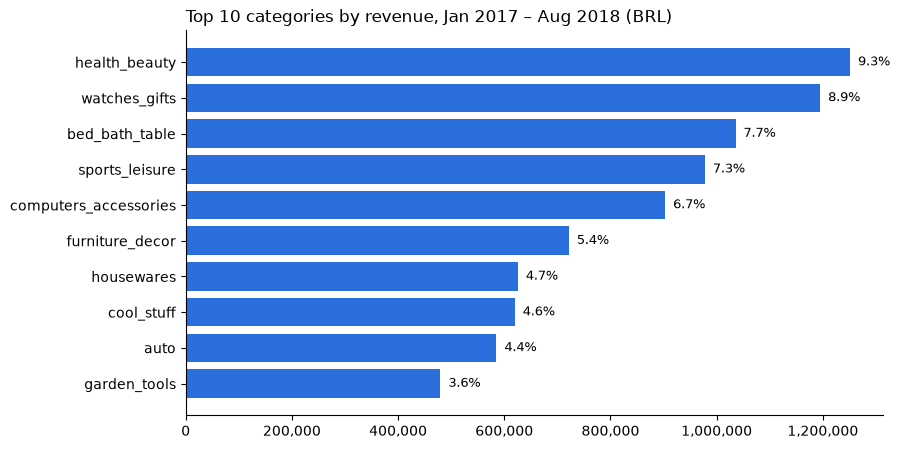

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

top10 = cat.head(10).iloc[::-1]          # reverse so the biggest bar is on top
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10["category"], top10["revenue"], color="#2a6fdb")
for y, (rev, share) in enumerate(zip(top10["revenue"], top10["share_pct"])):
    ax.text(rev, y, f"  {share:.1f}%", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Top 10 categories by revenue, Jan 2017 – Aug 2018 (BRL)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [6]:
sellers = (items.groupby("seller_id", as_index=False)["revenue"].sum()
                .sort_values("revenue", ascending=False)
                .reset_index(drop=True))
sellers["cum_share_pct"] = sellers["revenue"].cumsum() / sellers["revenue"].sum() * 100
sellers["seller_pct"]    = (sellers.index + 1) / len(sellers) * 100

top20 = sellers.loc[sellers["seller_pct"] <= 20, "revenue"].sum() / sellers["revenue"].sum() * 100
print(f"{len(sellers):,} sellers")
print(f"Top 20% of sellers bring in {top20:.1f}% of revenue")

3,029 sellers
Top 20% of sellers bring in 82.5% of revenue


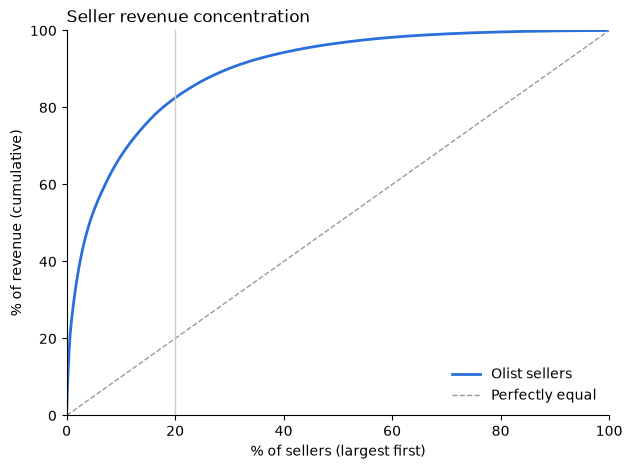

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sellers["seller_pct"], sellers["cum_share_pct"], color="#2a6fdb", linewidth=2, label="Olist sellers")
ax.plot([0, 100], [0, 100], color="#999999", linestyle="--", linewidth=1, label="Perfectly equal")
ax.axvline(20, color="#cccccc", linewidth=1)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel("% of sellers (largest first)")
ax.set_ylabel("% of revenue (cumulative)")
ax.set_title("Seller revenue concentration", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Findings
- **Total revenue (Jan 2017 – Aug 2018): 13.45M BRL**, reconciled with notebook 01.
- **Categories: moderately concentrated.** The top 10 of 74 categories (~14%) bring in 62.4% of revenue. No single-category dependency.
- **Sellers: highly concentrated (80/20).** The top 20% of 3,029 sellers bring in 82.5% of revenue; roughly the top 5% bring in about half. The bottom half contributes only ~3%.
- **Implication:** protect the top sellers (dependency risk); the long tail is a growth opportunity.
- **Caveat:** sellers who joined later had less time to sell, so part of the long tail reflects tenure, not performance.